<a href="https://colab.research.google.com/github/Shreshta1234/Fellowship-training-868661/blob/main/Phase%201/Shreshta_Nagaraju_Day_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install kagglehub
import kagglehub, glob, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt

path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")
csv = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df = pd.read_csv(csv)
print(df.columns.tolist())
print(df.head())

Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [3]:

thr = df["rainfall"].quantile(0.40)
df["needs_water"] = (df["rainfall"] < thr).astype(int)


features = ["N", "P", "K", "temperature", "humidity", "ph"]
X = df[features].values
y = df["needs_water"].values

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

scaler = StandardScaler().fit(Xtr)
Xtr, Xte = scaler.transform(Xtr), scaler.transform(Xte)
print("Class balance (train):", np.bincount(ytr))

Class balance (train): [990 660]


In [4]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, roc_auc_score, accuracy_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)

m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
proba = m.predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)

print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(yte, pred))
print(f"Accuracy : {accuracy_score(yte, pred):.3f}")
print(f"Precision: {precision_score(yte, pred):.3f}")
print(f"Recall   : {recall_score(yte, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(yte, proba):.3f}")

print("\nCoefficients (standardized features):")
for f, c in zip(features, m.coef_[0]):
    print(f"  {f:12s} {c:+.3f}")

Confusion matrix [[TN FP] [FN TP]]:
 [[283  47]
 [156  64]]
Accuracy : 0.631
Precision: 0.577
Recall   : 0.291
ROC-AUC  : 0.623

Coefficients (standardized features):
  N            +0.024
  P            +0.139
  K            +0.166
  temperature  +0.294
  humidity     -0.088
  ph           +0.501


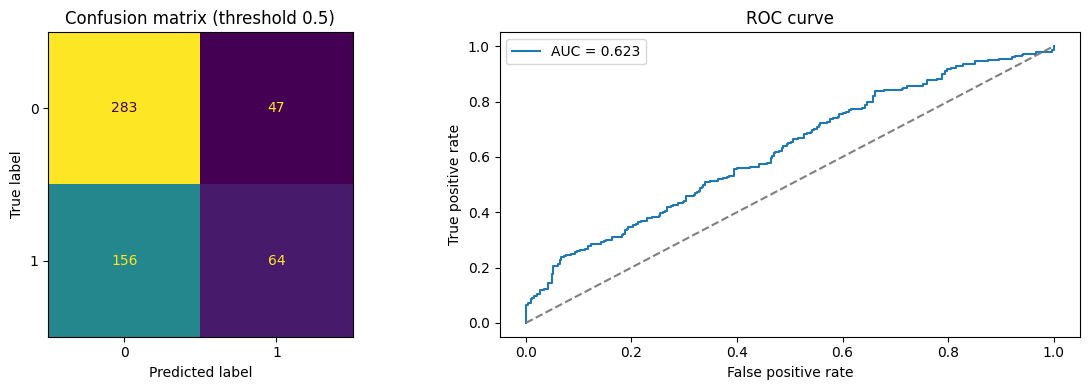

threshold 0.7: recall=0.06  precision=1.00  false alarms=0
threshold 0.5: recall=0.29  precision=0.58  false alarms=47
threshold 0.3: recall=0.86  precision=0.43  false alarms=248
threshold 0.2: recall=0.97  precision=0.40  false alarms=316


In [6]:

from sklearn.metrics import roc_curve

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(yte, pred, ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")

fpr, tpr, _ = roc_curve(yte, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(yte, proba):.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax[1].legend()
plt.tight_layout(); plt.show()


for t in [0.7, 0.5, 0.3, 0.2]:
    p = (proba >= t).astype(int)
    print(f"threshold {t}: recall={recall_score(yte, p):.2f}  "
          f"precision={precision_score(yte, p):.2f}  false alarms={((p==1)&(yte==0)).sum()}")